# Data Cleaning and Exploratory Analysis

In this notebook, we will prepare the historical game data and explore its main patterns. We will:

1. Restrict the data to completed FBS-vs-FBS games
2. Create one record per team and game
3. Check duplicate records and missing values
4. Examine score, margin, total, home-field, and season-level trends
5. Save the cleaned team-game table

In [1]:
from pathlib import Path
import sys

# Allow the notebook to run from either the project root or the notebooks folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

## Imports and Data

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import FIGURE_DIR, INTERIM_DIR
from src.data import load_interim_data
from src.features import build_team_games
from src.visualization import COLORS, set_plot_style

pd.set_option('display.max_columns', 100)
set_plot_style()

tables = load_interim_data()
games = tables['games']

Matplotlib is building the font cache; this may take a moment.


## Cleaning the Game Table

In [3]:
fbs_games = games[
    games['home_classification'].eq('fbs') &
    games['away_classification'].eq('fbs')
].copy()

completed_games = fbs_games[
    fbs_games['completed'].eq(True) &
    fbs_games['home_points'].notna() &
    fbs_games['away_points'].notna()
].copy()

completed_games['margin'] = completed_games['home_points'] - completed_games['away_points']
completed_games['total'] = completed_games['home_points'] + completed_games['away_points']

print('Completed FBS-vs-FBS games:', len(completed_games))
print('Duplicate game IDs:', completed_games['game_id'].duplicated().sum())
print('Seasons:', completed_games['season'].min(), 'through', completed_games['season'].max())

Completed FBS-vs-FBS games: 9242
Duplicate game IDs: 0
Seasons: 2014 through 2026


In [4]:
team_games = build_team_games(
    games=fbs_games,
    team_stats=tables['team_stats'],
    advanced_stats=tables['advanced_stats'],
)

team_games.to_csv(INTERIM_DIR / 'team_games.csv', index=False)
print('Shape of the team-game dataset:', team_games.shape)
team_games.head()

Shape of the team-game dataset: (18484, 107)


,game_id,season,week,season_type,start_date,team,opponent,points_for,points_against,is_home,fumbles_recovered,rushing_tds,punt_return_yards,punt_return_tds,punt_returns,passing_tds,kick_return_yards,kick_return_tds,kick_returns,kicking_points,possession_seconds,interceptions,fumbles_lost,turnovers,penalties,penalty_yards,yards_per_rush_attempt,rushing_attempts,rushing_yards,yards_per_pass,completions,pass_attempts,net_passing_yards,total_yards,fourth_down_conversions,fourth_down_attempts,third_down_conversions,third_down_attempts,first_downs,interception_yards,interception_tds,passes_intercepted,total_fumbles,tackles_for_loss,defensive_tds,tackles,sacks,qb_hurries,passes_deflected,third_down_pct,...,offense_power_success,offense_stuff_rate,offense_line_yards,offense_line_yards_total,offense_second_level_yards,offense_second_level_yards_total,offense_open_field_yards,offense_open_field_yards_total,offense_standard_downs_ppa,offense_standard_downs_success_rate,offense_standard_downs_explosiveness,offense_passing_downs_ppa,offense_passing_downs_success_rate,offense_passing_downs_explosiveness,offense_rushing_plays_ppa,offense_rushing_plays_total_ppa,offense_rushing_plays_success_rate,offense_rushing_plays_explosiveness,offense_passing_plays_ppa,offense_passing_plays_total_ppa,offense_passing_plays_success_rate,offense_passing_plays_explosiveness,defense_plays,defense_drives,defense_ppa,defense_total_ppa,defense_success_rate,defense_explosiveness,defense_power_success,defense_stuff_rate,defense_line_yards,defense_line_yards_total,defense_second_level_yards,defense_second_level_yards_total,defense_open_field_yards,defense_open_field_yards_total,defense_standard_downs_ppa,defense_standard_downs_success_rate,defense_standard_downs_explosiveness,defense_passing_downs_ppa,defense_passing_downs_success_rate,defense_passing_downs_explosiveness,defense_rushing_plays_ppa,defense_rushing_plays_total_ppa,defense_rushing_plays_success_rate,defense_rushing_plays_explosiveness,defense_passing_plays_ppa,defense_passing_plays_total_ppa,defense_passing_plays_success_rate,defense_passing_plays_explosiveness
0,400548402,2014,1,regular,2014-08-28 22:00:00+00:00,Texas A&M,South Carolina,52.0,28.0,0,0.0,4.0,7.0,0.0,2.0,3.0,32.0,0.0,1.0,10.0,2258.0,0.0,0.0,0.0,8.0,95.0,4.3,39.0,169.0,8.5,44.0,60.0,511.0,680.0,2.0,2.0,12.0,17.0,39.0,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.705882,...,1.000000,0.105263,3.260526,124.0,1.105263,42.0,0.657895,25.0,0.211638,0.526316,0.895502,1.156171,0.583333,2.098034,0.378704,14.390740,0.500000,1.103691,0.494431,30.160262,0.557377,1.321789,62.0,11.0,0.186328,11.552323,0.435484,1.465430,1.000000,0.157895,3.368421,64.0,0.842105,16.0,0.210526,4.0,0.371247,0.545455,1.315987,-0.265696,0.166667,2.660979,0.021520,0.408871,0.526316,0.599616,0.259150,11.143452,0.395349,1.974732
1,400548402,2014,1,regular,2014-08-28 22:00:00+00:00,South Carolina,Texas A&M,28.0,52.0,1,0.0,0.0,NaN,NaN,NaN,4.0,55.0,0.0,3.0,4.0,1342.0,1.0,0.0,1.0,4.0,21.0,3.0,22.0,67.0,9.1,20.0,40.0,366.0,433.0,0.0,1.0,2.0,9.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.222222,...,1.000000,0.157895,3.368421,64.0,0.842105,16.0,0.210526,4.0,0.371247,0.545455,1.315987,-0.265696,0.166667,2.660979,0.021520,0.408871,0.526316,0.599616,0.259150,11.143452,0.395349,1.974732,100.0,12.0,0.438326,43.832597,0.540000,1.207269,1.000000,0.105263,3.260526,124.0,1.105263,42.0,0.657895,25.0,0.211638,0.526316,0.895502,1.156171,0.583333,2.098034,0.378704,14.390740,0.500000,1.103691,0.494431,30.160262,0.557377,1.321789
2,400547829,2014,1,regular,2014-08-28 23:00:00+00:00,Wake Forest,UL Monroe,10.0,17.0,0,1.0,0.0,35.0,1.0,2.0,0.0,14.0,0.0,1.0,4.0,1477.0,1.0,0.0,1.0,8.0,51.0,-0.1,27.0,-3.0,4.4,12.0,22.0,97.0,94.0,0.0,0.0,3.0,14.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.214286,...,0.666667,0.300000,2.290000,46.0,0.450000,9.0,0.000000,0.0,-0.194289,0.300000,0.581224,-0.411539,0.100000,0.608687,-0.232139,-4.642778,0.150000,0.142234,-0.309753,-8.982832,0.241379,0.922219,87.0,13.0,-0.133467,

Each completed game should appear twice in `team_games`: once from the home team's perspective and once from the away team's perspective. This format will make it easier to calculate rolling team statistics without duplicating feature logic.

In [5]:
records_per_game = team_games.groupby('game_id').size()
print('Games without exactly two team records:', records_per_game.ne(2).sum())

missing_summary = (
    team_games.isna().mean()
    .sort_values(ascending=False)
    .rename('missing proportion')
    .to_frame()
)
missing_summary.head(20)

Games without exactly two team records: 0


,missing proportion
interception_yards,0.442491
interception_tds,0.442491
passes_intercepted,0.442491
total_fumbles,0.395694
punt_returns,0.297068
punt_return_yards,0.297068
punt_return_tds,0.297068
fourth_down_pct,0.194276
defensive_tds,0.171878
qb_hurries,0.171878


## Score Distributions

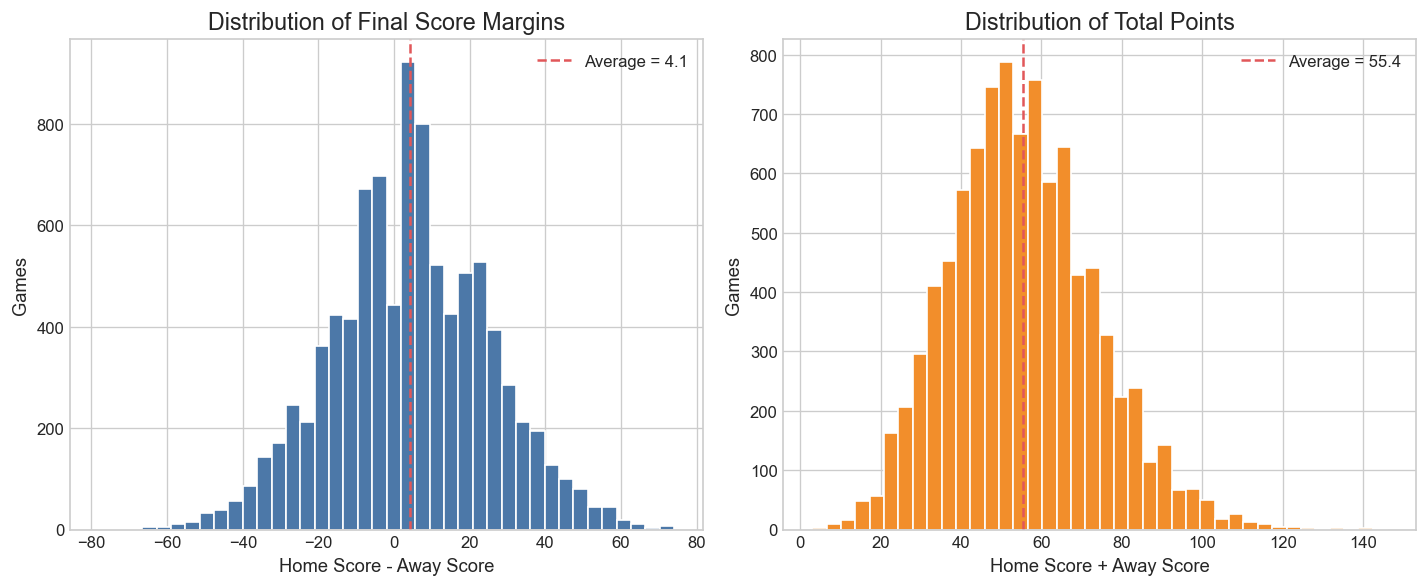

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(completed_games['margin'], bins=40, color=COLORS['blue'], edgecolor='white')
axes[0].axvline(completed_games['margin'].mean(), color=COLORS['red'], linestyle='--',
                label=f"Average = {completed_games['margin'].mean():.1f}")
axes[0].set(title='Distribution of Final Score Margins', xlabel='Home Score - Away Score', ylabel='Games')
axes[0].legend()

axes[1].hist(completed_games['total'], bins=40, color=COLORS['orange'], edgecolor='white')
axes[1].axvline(completed_games['total'].mean(), color=COLORS['red'], linestyle='--',
                label=f"Average = {completed_games['total'].mean():.1f}")
axes[1].set(title='Distribution of Total Points', xlabel='Home Score + Away Score', ylabel='Games')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'score_distributions.png', bbox_inches='tight')
plt.show()

Margin is centered to the right of zero because non-neutral home teams have an advantage on average. Both distributions have long tails, so we will use mean absolute error as the primary metric and RMSE as a secondary metric that penalizes large misses more heavily.

## Home-Field Advantage

In [7]:
home_advantage = (
    completed_games.assign(neutral=completed_games['neutral_site'].map({True: 'Neutral', False: 'Home field'}))
    .groupby('neutral')['margin']
    .agg(['count', 'mean', 'median'])
)
home_advantage

,count,mean,median
neutral,,,
Home field,8515,4.409160,4.0
Neutral,727,0.891334,1.0


## Scoring Over Time

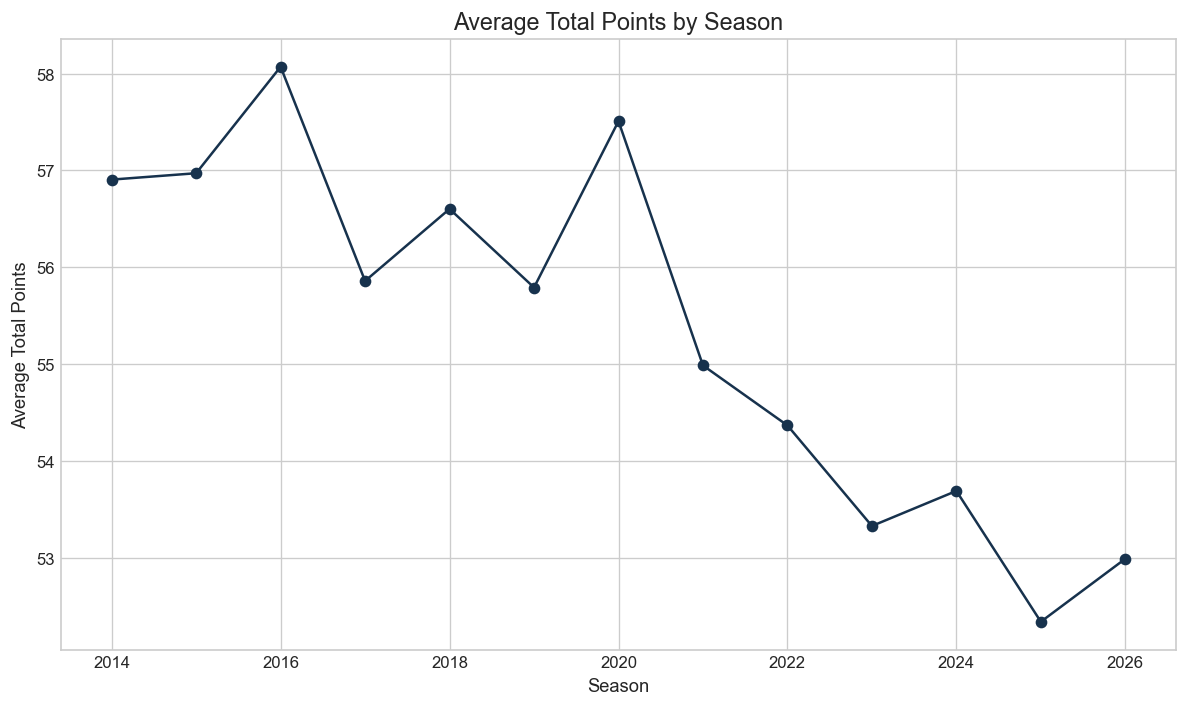

,season,games,average_total,average_margin
0,2014,760,56.903947,3.630263
1,2015,765,56.969935,3.966013
2,2016,760,58.069737,4.177632
3,2017,776,55.856959,3.990979
4,2018,772,56.601036,4.235751
5,2019,774,55.789406,4.425065
6,2020,534,57.507491,2.088015
7,2021,770,54.984416,3.259740
8,2022,776,54.364691,3.725515
9,2023,792,53.325758,3.815657


In [8]:
season_summary = (
    completed_games.groupby('season')
    .agg(games=('game_id', 'size'), average_total=('total', 'mean'), average_margin=('margin', 'mean'))
    .reset_index()
)

fig, axis = plt.subplots()
axis.plot(season_summary['season'], season_summary['average_total'], marker='o', color=COLORS['navy'])
axis.set(title='Average Total Points by Season', xlabel='Season', ylabel='Average Total Points')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'scoring_by_season.png', bbox_inches='tight')
plt.show()

season_summary

## Advanced Statistic Coverage

In [9]:
advanced_columns = [
    column for column in team_games.columns
    if column.startswith('offense_') or column.startswith('defense_')
]

advanced_coverage = (
    team_games.groupby('season')[advanced_columns]
    .apply(lambda frame: frame.notna().mean().mean())
    .rename('average advanced feature coverage')
)
advanced_coverage.to_frame()

,average advanced feature coverage
season,
2014,0.978947
2015,0.990850
2016,0.982895
2017,0.994845
2018,0.997409
2019,0.998708
2020,1.000000
2021,1.000000
2022,1.000000


## Conclusion

The cleaned data contains two team records for each completed FBS-vs-FBS game. Missing values are expected for some advanced statistics, especially in earlier seasons and unusual games. We will retain these games and fit imputation only within each training fold rather than filling values before model validation.